# WICOS Project - Model 5: Random Forest on Hand-Crafted Features
In this notebook we classify the four radar hand gestures with a random forest (Lecture 8) on the same 27 hand-crafted features as Models 1 and 2. A random forest is bagging applied to decision trees: every tree is trained on a bootstrap sample of the training data, and at every split only a random subset of the features is considered. The trees are fully grown and not cross-validated one by one; their predictions are combined by voting, which averages out the overfitting of the individual trees. Note that sklearn's `RandomForestClassifier` combines the trees with a *soft* vote (it averages the class probabilities of the trees) instead of the hard majority vote of the lecture; with hundreds of trees the two give almost the same prediction.

Four hyperparameters are tuned: `max_features` (the number of features considered at each split, which controls how different the trees are), `max_depth` and `min_samples_leaf` (how complex each tree can become) and `n_estimators` (the number of trees). Because the trees are trained on bootstrap samples, the samples left out of a tree (out-of-bag, OOB) give a validation estimate for free. A random forest also ranks the features by importance, which we compare with the L1 selection of Model 1.

The aim of the project is to recognise a gesture *regardless of the person who performs it*. The 40 samples per person and gesture are cut from one continuous recording, so samples of the same person are very similar. With a random split, the model sees the test person during training and the score is too optimistic.

All models are therefore validated with **leave-one-person-out (LOPO)** cross-validation: the model is trained on five persons and tested on the sixth, once for every person. Hyperparameters are chosen with a second LOPO loop *inside* the five training persons (nested cross-validation), so the test person is never used to choose the model.

In [1]:
# Import packages needed for the lab
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, PredefinedSplit, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

C:\Users\hawma\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.5.3)
  from scipy.stats import gaussian_kde


In [2]:
SEED = 42
np.random.seed(SEED)

# Folders for the report figures and the results
FIG_DIR = Path("../reports/figures")
RES_DIR = Path("../results")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

## Task 1 - Data Preparation
- Load the prepared dataset and check the number of samples per person and gesture.

In [3]:
# Load the prepared dataset (created by src/prepare_data.py)
data = np.load("../data/processed/wicos_dataset.npz", allow_pickle=True)

X = data["X_feat"]                          # hand-crafted features, not scaled (not needed for trees)
y = data["y"]                               # 0=wave, 1=pinch, 2=swipe, 3=click
persons = data["persons"]                   # person who performed the gesture (A-F)
feature_names = list(data["feature_names"])
gestures = list(data["gestures"])

print("Feature matrix X: " + str(X.shape))
print("Label vector y:   " + str(y.shape))

Feature matrix X: (960, 27)
Label vector y:   (960,)


In [4]:
#Number of samples per person and gesture
pd.crosstab(persons, np.array(gestures)[y], rownames=["person"], colnames=["gesture"])

gesture,click,pinch,swipe,wave
person,,,,
A,40,40,40,40
B,40,40,40,40
C,40,40,40,40
D,40,40,40,40
E,40,40,40,40
F,40,40,40,40


A decision tree splits on one feature at a time with a threshold, so the result does not change when a feature is scaled. Unlike Models 1 and 2, no `StandardScaler` is needed.

The function `lopo_scores` computes the accuracy and macro-F1 score for every held-out person. Macro-F1 averages the F1 score of the four gestures, so every gesture counts equally. `print_scores` prints the mean ± standard deviation over the six persons.

In [5]:
def lopo_scores(y_true, y_pred, groups):
    # Accuracy and macro-F1 per held-out person
    rows = []
    for p in np.unique(groups):
        mask = groups == p
        rows.append({
            "person": p,
            "accuracy": accuracy_score(y_true[mask], y_pred[mask]),
            "f1_macro": f1_score(y_true[mask], y_pred[mask], average="macro"),
        })
    return pd.DataFrame(rows)


def print_scores(scores):
    # Mean and standard deviation over the six persons
    print("Accuracy: " + f"{scores.accuracy.mean():.3f} ± {scores.accuracy.std():.3f}")
    print("F1 score (macro): " + f"{scores.f1_macro.mean():.3f} ± {scores.f1_macro.std():.3f}")

In [6]:
def clean(params):
    # Short parameter names and rounded values for printing
    return {k.split("__")[-1]: (float(f"{v:.3g}") if isinstance(v, np.floating) else v) for k, v in params.items()}

## Task 2 - Baseline model
- Develop a `RandomForestClassifier` with default parameters (100 trees, fully grown, `max_features = sqrt(27) ≈ 5`).
- Predict every person with a model trained on the other five persons.
- Calculate and print the accuracy and macro-F1 score.

In [7]:
#Baseline random forest
clf_base = RandomForestClassifier(random_state=SEED, n_jobs=-1)

y_pred_base = cross_val_predict(clf_base, X, y, groups=persons, cv=LeaveOneGroupOut())
scores_base = lopo_scores(y, y_pred_base, persons)
print_scores(scores_base)
scores_base

Accuracy: 0.729 ± 0.099
F1 score (macro): 0.714 ± 0.117


,person,accuracy,f1_macro
0,A,0.63750,0.626057
1,B,0.60000,0.540871
2,C,0.74375,0.741615
3,D,0.73125,0.718936
4,E,0.79375,0.789224
5,F,0.86875,0.868587


## Task 3 - Number of trees and out-of-bag error
Adding trees does not make a random forest overfit: the vote only becomes more stable. We therefore do not tune `n_estimators` in the grid search, but choose it from the curve below as the point where the score stops improving.

- Train forests with an increasing number of trees and plot the out-of-bag (OOB) F1 score and the LOPO validation F1 score.

The OOB score uses the samples of the *same* persons that a tree did not see, so it behaves like a random split and is too optimistic for unseen persons. The LOPO curve shows the realistic score.

C:\Users\hawma\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\ensemble\_forest.py:615: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


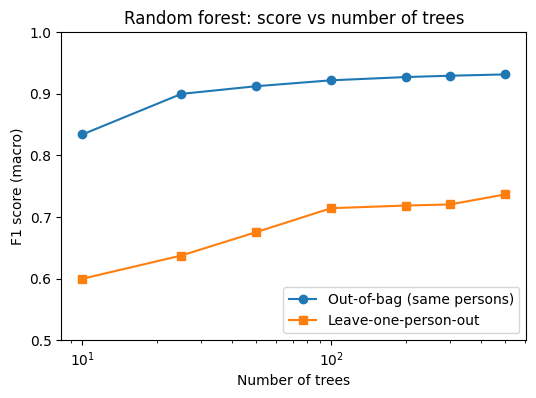

,n_estimators,OOB,LOPO
0,10,0.834,0.600
1,25,0.900,0.637
2,50,0.912,0.675
3,100,0.922,0.714
4,200,0.927,0.718
5,300,0.929,0.720
6,500,0.931,0.737


In [8]:
#OOB and LOPO score as a function of the number of trees
n_trees = [10, 25, 50, 100, 200, 300, 500]
curve = []
for n in n_trees:
    rf = RandomForestClassifier(n_estimators=n, oob_score=True, random_state=SEED, n_jobs=-1).fit(X, y)
    y_oob = rf.oob_decision_function_.argmax(axis=1)
    y_lopo = cross_val_predict(RandomForestClassifier(n_estimators=n, random_state=SEED, n_jobs=-1),
                               X, y, groups=persons, cv=LeaveOneGroupOut())
    curve.append({
        "n_estimators": n,
        "OOB": f1_score(y, y_oob, average="macro"),
        "LOPO": lopo_scores(y, y_lopo, persons).f1_macro.mean(),
    })
curve = pd.DataFrame(curve)

plt.figure(figsize=(6, 4))
plt.plot(curve.n_estimators, curve.OOB, "o-", label="Out-of-bag (same persons)")
plt.plot(curve.n_estimators, curve.LOPO, "s-", label="Leave-one-person-out")
plt.xscale("log")
plt.ylim(0.5, 1)
plt.xlabel("Number of trees")
plt.ylabel("F1 score (macro)")
plt.title("Random forest: score vs number of trees")
plt.legend(loc="lower right")
plt.savefig(FIG_DIR / "rf_n_estimators.pdf", bbox_inches="tight")
plt.show()
curve.round(3)

## Task 4 - Hyperparameter tuning
- Fix the number of trees at 300 (Task 3) and run a grid search over `max_features`, `max_depth` and `min_samples_leaf` with LOPO cross-validation on all six persons.
- Plot the training and validation macro-F1 for every combination of `max_features` and `max_depth` as heat maps.

`max_depth` and `min_samples_leaf` limit how far each tree is grown, which corresponds to the "early stopping" technique for recursively defined trees in Lecture 8. We do not tune the other technique of the lecture, pruning (`ccp_alpha`), because limiting the depth already controls the same tree capacity and the lecture's random forest uses fully grown trees anyway.

The scores in this task are used to *study* the hyperparameters; the unbiased estimate follows in Task 5.

In [9]:
#Random forest and hyperparameter grid
N_TREES = 300
clf = RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, n_jobs=1)

param_grid = {
    "max_features": [1, "sqrt", 0.5, 1.0],          # 1, 5, 13 or all 27 features per split
    "max_depth": [3, 5, 10, None],
    "min_samples_leaf": [1, 5, 20],
}

#Grid search with leave-one-person-out cross-validation
search_all = GridSearchCV(clf, param_grid, cv=LeaveOneGroupOut(), scoring="f1_macro", n_jobs=-1, return_train_score=True)
search_all.fit(X, y, groups=persons)
print("Best parameters: " + str(clean(search_all.best_params_)))
print("Best validation F1 score (macro): " + str(round(search_all.best_score_, 3)))

Best parameters: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5}
Best validation F1 score (macro): 0.74


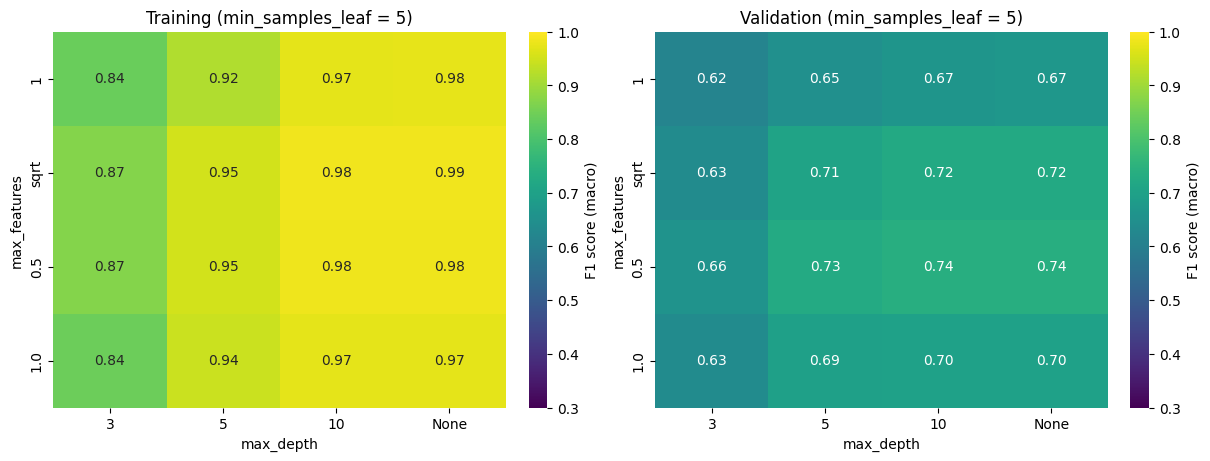

In [10]:
#Heat maps of the training and validation score over max_features and max_depth
results = pd.DataFrame(search_all.cv_results_)
results["max_features"] = results.params.apply(lambda p: str(p["max_features"]))
results["max_depth"] = results.params.apply(lambda p: str(p["max_depth"]))
best_leaf = search_all.best_params_["min_samples_leaf"]
r = results[results.param_min_samples_leaf == best_leaf]

feature_order = ["1", "sqrt", "0.5", "1.0"]
depth_order = ["3", "5", "10", "None"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, score, title in zip(axes, ["mean_train_score", "mean_test_score"], ["Training", "Validation"]):
    table = r.pivot_table(index="max_features", columns="max_depth", values=score).loc[feature_order, depth_order]
    sn.heatmap(table, annot=True, fmt=".2f", cmap="viridis", vmin=0.3, vmax=1, ax=ax, cbar_kws={"label": "F1 score (macro)"})
    ax.set_title(f"{title} (min_samples_leaf = {best_leaf})")
    ax.set_xlabel("max_depth")
    ax.set_ylabel("max_features")
fig.savefig(FIG_DIR / "rf_grid.pdf", bbox_inches="tight")
plt.show()

In [11]:
#Effect of min_samples_leaf (best validation score over the other hyperparameters)
results.groupby("param_min_samples_leaf")[["mean_train_score", "mean_test_score"]].max().round(3) \
    .rename(columns={"mean_train_score": "best training F1", "mean_test_score": "best validation F1"})

,best training F1,best validation F1
param_min_samples_leaf,,
1,1.000,0.730
5,0.985,0.740
20,0.929,0.692


## Task 5 - Nested leave-one-person-out evaluation
- For every person: tune `max_features`, `max_depth` and `min_samples_leaf` with a LOPO grid search on the other five persons, then test the best model once on the held-out person.
- Calculate and print the accuracy and macro-F1 score (mean ± std over the six persons).
- Plot the accuracy per person and the confusion matrix.

In [12]:
#Nested leave-one-person-out
logo = LeaveOneGroupOut()
y_pred_nested = np.zeros_like(y)
best_params = []

for train_idx, test_idx in logo.split(X, y, groups=persons):
    person = persons[test_idx][0]

    # Inner loop: tune the hyperparameters on the five training persons only
    search = GridSearchCV(clf, param_grid, cv=LeaveOneGroupOut(), scoring="f1_macro", n_jobs=-1)
    search.fit(X[train_idx], y[train_idx], groups=persons[train_idx])

    # Outer loop: test once on the held-out person
    y_pred_nested[test_idx] = search.predict(X[test_idx])
    best_params.append({"person": person, **clean(search.best_params_)})
    print(f"Person {person} held out -> best parameters: {best_params[-1]}")

scores_nested = lopo_scores(y, y_pred_nested, persons).merge(pd.DataFrame(best_params), on="person")
scores_nested

Person A held out -> best parameters: {'person': 'A', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1}
Person B held out -> best parameters: {'person': 'B', 'max_depth': 5, 'max_features': 1.0, 'min_samples_leaf': 5}
Person C held out -> best parameters: {'person': 'C', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1}
Person D held out -> best parameters: {'person': 'D', 'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1}
Person E held out -> best parameters: {'person': 'E', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1}
Person F held out -> best parameters: {'person': 'F', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1}


,person,accuracy,f1_macro,max_depth,max_features,min_samples_leaf
0,A,0.63125,0.626094,10.0,sqrt,1
1,B,0.37500,0.250500,5.0,1.0,5
2,C,0.74375,0.741782,10.0,sqrt,1
3,D,0.73125,0.714069,NaN,0.5,1
4,E,0.76875,0.753961,5.0,sqrt,1
5,F,0.83125,0.827818,10.0,sqrt,1


In [13]:
#Performance metrics
print("Baseline:")
print_scores(scores_base)
print("Tuned (nested LOPO):")
print_scores(scores_nested)

Baseline:
Accuracy: 0.729 ± 0.099
F1 score (macro): 0.714 ± 0.117
Tuned (nested LOPO):
Accuracy: 0.680 ± 0.163
F1 score (macro): 0.652 ± 0.207


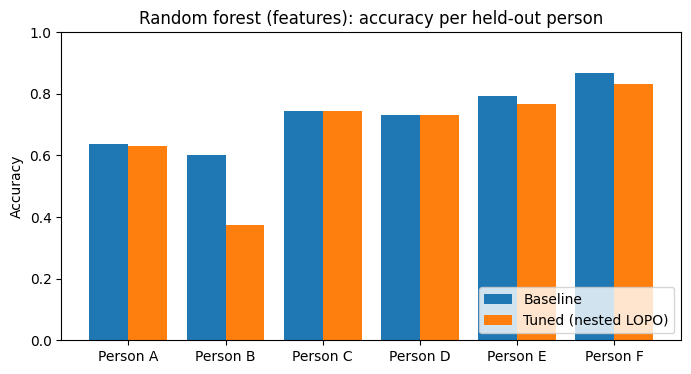

In [14]:
#Accuracy per held-out person: baseline vs tuned model
x = np.arange(len(scores_nested))

plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, scores_base.accuracy, width=0.4, label="Baseline")
plt.bar(x + 0.2, scores_nested.accuracy, width=0.4, label="Tuned (nested LOPO)")
plt.xticks(x, ["Person " + p for p in scores_nested.person])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Random forest (features): accuracy per held-out person")
plt.legend(loc="lower right")
plt.savefig(FIG_DIR / "rf_per_person.pdf", bbox_inches="tight")
plt.show()

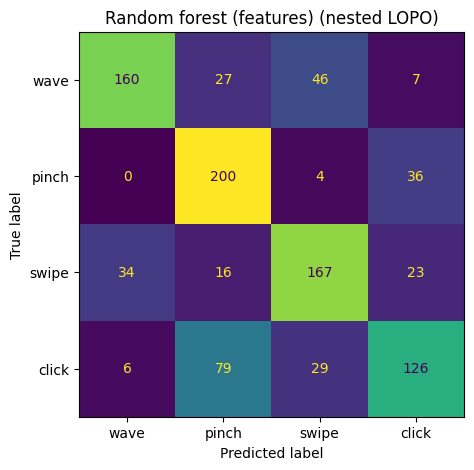

In [15]:
#Confusion matrix of the tuned model, summed over the six held-out persons
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y, y_pred_nested, display_labels=gestures, ax=ax, colorbar=False)
ax.set_title("Random forest (features) (nested LOPO)")
fig.savefig(FIG_DIR / "rf_confusion_matrix.pdf", bbox_inches="tight")
plt.show()

## Task 6 - Feature importance
A random forest gives two kinds of feature importance:
- **Impurity-based (MDI)**: how much a feature decreases the Gini impurity, summed over all splits in all trees. It is computed on the training data and favours features with many distinct values.
- **Permutation importance**: how much the validation score drops when the values of one feature are shuffled. We compute it on the held-out person of every LOPO fold, so it measures what generalises to new persons.

- Train the forest with the best parameters of Task 4 and plot both importances for the 15 most important features.

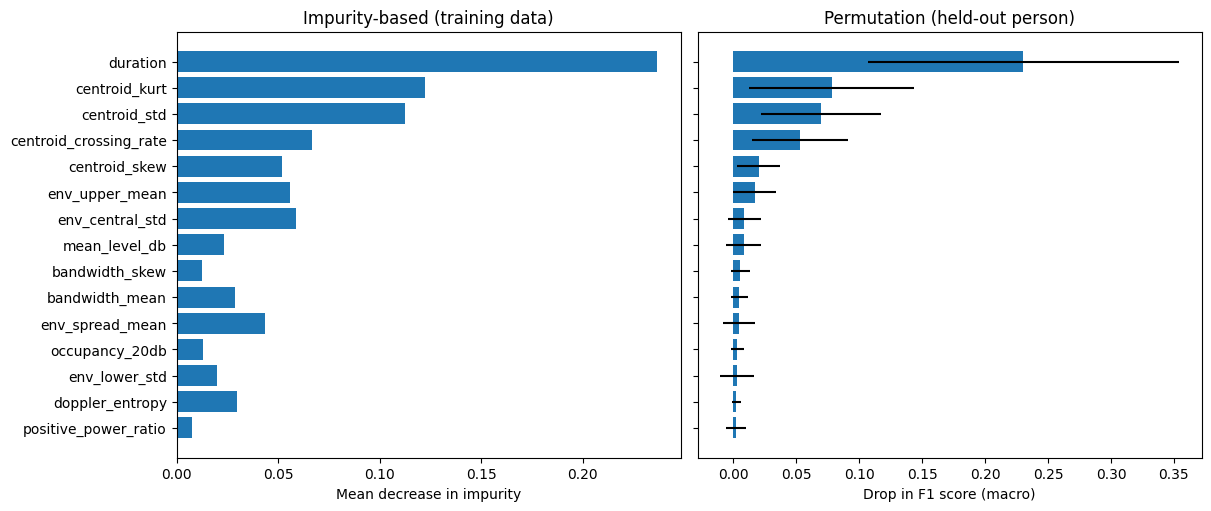

,MDI,permutation_mean,permutation_std
duration,0.236,0.230,0.123
centroid_kurt,0.122,0.078,0.065
centroid_std,0.112,0.069,0.047
centroid_crossing_rate,0.067,0.053,0.038
centroid_skew,0.052,0.020,0.017
env_upper_mean,0.056,0.017,0.017
env_central_std,0.059,0.009,0.013
mean_level_db,0.023,0.008,0.014
bandwidth_skew,0.012,0.006,0.007
bandwidth_mean,0.029,0.005,0.007


In [16]:
#Impurity-based and permutation importance (permutation on the held-out person of each LOPO fold)
best_rf = search_all.best_estimator_
mdi = pd.Series(best_rf.feature_importances_, index=feature_names)

perm = []
for train_idx, test_idx in logo.split(X, y, groups=persons):
    rf = RandomForestClassifier(**{**best_rf.get_params(), "n_jobs": -1}).fit(X[train_idx], y[train_idx])
    pi = permutation_importance(rf, X[test_idx], y[test_idx], scoring="f1_macro", n_repeats=10, random_state=SEED, n_jobs=-1)
    perm.append(pi.importances_mean)
perm = pd.DataFrame(perm, columns=feature_names)

importance = pd.DataFrame({
    "MDI": mdi,
    "permutation_mean": perm.mean(),
    "permutation_std": perm.std(),
}).sort_values("permutation_mean", ascending=False)

top = importance.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, constrained_layout=True)
axes[0].barh(top.index, top.MDI)
axes[0].set_xlabel("Mean decrease in impurity")
axes[0].set_title("Impurity-based (training data)")
axes[1].barh(top.index, top.permutation_mean, xerr=top.permutation_std)
axes[1].set_xlabel("Drop in F1 score (macro)")
axes[1].set_title("Permutation (held-out person)")
fig.savefig(FIG_DIR / "rf_feature_importance.pdf", bbox_inches="tight")
plt.show()
importance.round(3)

## Task 7 - Comparison with a random split
The data exploration notebook (`wicos.ipynb`) uses a random, stratified 80/20 split. To show why we validate per person, the same model is tuned with the random 5-fold cross-validation of that notebook and tested on its random 20% test set.

- Tune the model with the predefined random folds (`cv_fold`) on the training set.
- Test it on the random test set and compare the score with the LOPO result.

In [17]:
#Random split: tune with the random 5-fold CV, test on the random 20% test set
idx_train, idx_test, cv_fold = data["idx_train"], data["idx_test"], data["cv_fold"]

search_rs = GridSearchCV(clf, param_grid, cv=PredefinedSplit(cv_fold[idx_train]), scoring="f1_macro", n_jobs=-1)
search_rs.fit(X[idx_train], y[idx_train])
y_pred_rs = search_rs.predict(X[idx_test])

accuracy_rs = accuracy_score(y[idx_test], y_pred_rs)
f1_rs = f1_score(y[idx_test], y_pred_rs, average="macro")
print("Best parameters: " + str(clean(search_rs.best_params_)))
print("Accuracy: " + str(round(accuracy_rs, 3)))
print("F1 score (macro): " + str(round(f1_rs, 3)))

Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}
Accuracy: 0.906
F1 score (macro): 0.907


In [18]:
#Random split vs leave-one-person-out
comparison = pd.DataFrame({
    "Accuracy": [accuracy_rs, scores_nested.accuracy.mean()],
    "F1 score (macro)": [f1_rs, scores_nested.f1_macro.mean()],
}, index=["Random 80/20 split", "Leave-one-person-out (mean)"])
comparison.round(3)

,Accuracy,F1 score (macro)
Random 80/20 split,0.906,0.907
Leave-one-person-out (mean),0.680,0.652


## Task 8 - Save the results
The per-person scores and a one-line summary are saved in `results/`, so all models can be compared in one table.

In [19]:
#Save the results
scores_nested.to_csv(RES_DIR / "random_forest_lopo.csv", index=False)
importance.to_csv(RES_DIR / "random_forest_feature_importance.csv")

summary = pd.DataFrame([{
    "model": "Random forest (features)",
    "lopo_accuracy_mean": scores_nested.accuracy.mean(),
    "lopo_accuracy_std": scores_nested.accuracy.std(),
    "lopo_f1_mean": scores_nested.f1_macro.mean(),
    "lopo_f1_std": scores_nested.f1_macro.std(),
    "random_split_accuracy": accuracy_rs,
    "random_split_f1": f1_rs,
}])
summary.to_csv(RES_DIR / "random_forest_summary.csv", index=False)
summary.round(3)

,model,lopo_accuracy_mean,lopo_accuracy_std,lopo_f1_mean,lopo_f1_std,random_split_accuracy,random_split_f1
0,Random forest (features),0.68,0.163,0.652,0.207,0.906,0.907
